# Monthly Skill Trends for U.S. Data Analysts

This notebook examines how demand for the leading Data Analyst skills changes from month to month in U.S. job postings. Skill mentions are expressed as a share of monthly postings so that changes in overall hiring volume do not distort the comparison.

## Analysis approach

1. Prepare the job-postings dataset and isolate U.S. Data Analyst roles.
2. Assign each posting to a calendar month and expand its listed skills.
3. Count skill mentions by month and rank skills by total demand.
4. Normalize monthly counts by the number of Data Analyst postings.
5. Plot the monthly prevalence of the five leading skills.

## Load and prepare the data

Import the analysis libraries, load the job-postings dataset, and convert the posting date and skills columns into usable Python data types.

In [1]:
# Importing Libraries
import ast

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from datasets import load_dataset

# Loading Data
dataset = load_dataset("lukebarousse/data_jobs")
df = dataset["train"].to_pandas()

# Data Cleanup
df["job_posted_date"] = pd.to_datetime(df["job_posted_date"])
df["job_skills"] = df["job_skills"].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

d:\Data_Analyst\Resources\Code\Python\Python_Data_Analytics_Course\Playground\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Define the market and role

Filter the data to postings classified as **Data Analyst** roles in the **United States**, then establish a consistent visual theme.

In [4]:
# Only get data analyst jobs
df_DA_US = df[
	(df["job_title_short"] == "Data Analyst") & (df["job_country"] == "United States")
].copy()

# Set Theme
sns.set_theme(style="ticks", font_scale=1.2)

## Assign postings to months

Extract the numeric month from each posting date. This becomes the time grain used throughout the trend analysis.

In [5]:
df_DA_US["job_posted_month_num"] = df["job_posted_date"].dt.month

## Expand the skills field

Create one row for every posting-skill combination so that individual skill mentions can be aggregated by month.

In [6]:
df_DA_US_explode = df_DA_US.explode("job_skills")

## Build the monthly skill matrix

Pivot the expanded data into monthly skill counts, fill missing combinations with zero, and order the skill columns by their total number of mentions across the full period.

In [ ]:
df_DA_US_pivot = df_DA_US_explode.pivot_table(
	index="job_posted_month_num", columns="job_skills", aggfunc="size", fill_value=0
)
df_DA_US_pivot.loc["Total"] = df_DA_US_pivot.sum()
df_DA_US_pivot = df_DA_US_pivot[df_DA_US_pivot.loc["Total"].sort_values(ascending=False).index]
df_DA_US_pivot = df_DA_US_pivot.drop("Total")

df_DA_US_pivot

job_skills,sql,excel,tableau,python,sas,r,power bi,word,powerpoint,oracle,...,capacitor,chainer,asp.net core,qt,microsoft lists,msaccess,kotlin,openstack,theano,xamarin
job_posted_month_num,,,,,,,,,,,,,,,,,,,,,
1,4601,3592,2488,2254,1832,1513,1337,968,972,718,...,1,0,0,0,0,0,0,0,0,0
2,3168,2587,1676,1618,1212,1045,1122,738,705,514,...,0,0,0,0,0,0,0,0,0,0
3,3226,2661,1804,1683,1238,1141,1054,736,669,418,...,0,0,0,0,0,0,0,0,0,1
4,3220,2549,1789,1679,1302,1038,1057,695,650,439,...,0,0,0,0,0,0,0,0,0,0
5,2581,2118,1432,1349,972,867,860,557,515,358,...,0,0,0,0,0,1,0,0,0,0
6,2862,2382,1628,1609,984,1017,989,721,624,414,...,0,0,0,1,0,0,1,1,0,0
7,2609,2118,1533,1438,996,881,881,587,549,401,...,0,0,0,0,0,0,0,0,0,0
8,3414,2731,1951,2025,1276,1271,1208,752,746,484,...,0,0,0,0,0,0,0,0,0,0
9,2295,1801,1353,1229,856,746,820,478,475,359,...,0,0,0,0,0,0,0,0,0,0


## Count monthly job postings

Calculate the total number of U.S. Data Analyst postings in each month. These totals serve as the denominators for the normalized trend measure.

In [12]:
DA_totals = df_DA_US.groupby("job_posted_month_num").size()

DA_totals

job_posted_month_num
1     8494
2     6124
3     6218
4     6049
5     4993
6     5683
7     5201
8     6634
9     4639
10    5271
11    4531
12    3979
dtype: int64

## Convert counts to monthly percentages

Divide each monthly skill count by that month's total postings and multiply by 100. The resulting percentage estimates how likely a skill is to appear in a posting during each month.

In [33]:
df_DA_US_percent = df_DA_US_pivot.div(DA_totals / 100, axis=0)
df_DA_US_percent = df_DA_US_percent.reset_index()
df_DA_US_percent["job_posted_month"] = df_DA_US_percent["job_posted_month_num"].apply(
	lambda x: pd.to_datetime(x, format="%m").strftime("%b")
)
df_DA_US_percent = df_DA_US_percent.set_index("job_posted_month")
df_DA_US_percent = df_DA_US_percent.drop(columns="job_posted_month_num")

df_DA_US_percent

job_skills,sql,excel,tableau,python,sas,r,power bi,word,powerpoint,oracle,...,capacitor,chainer,asp.net core,qt,microsoft lists,msaccess,kotlin,openstack,theano,xamarin
job_posted_month,,,,,,,,,,,,,,,,,,,,,
Jan,54.167648,42.288674,29.291264,26.536379,21.568166,17.812574,15.740523,11.396280,11.443372,8.453026,...,0.011773,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Feb,51.730895,42.243632,27.367734,26.420640,19.790986,17.064010,18.321359,12.050947,11.512084,8.393207,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Mar,51.881634,42.795111,29.012544,27.066581,19.909939,18.349952,16.950788,11.836603,10.759087,6.722419,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.016082
Apr,53.231939,42.139197,29.575136,27.756654,21.524219,17.159861,17.473963,11.489502,10.745578,7.257398,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
May,51.692369,42.419387,28.680152,27.017825,19.467254,17.364310,17.224114,11.155618,10.314440,7.170038,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.020028,0.000000,0.000000,0.000000,0.000000
Jun,50.360725,41.914482,28.646841,28.312511,17.314799,17.895478,17.402780,12.686961,10.980116,7.284885,...,0.000000,0.000000,0.000000,0.017596,0.000000,0.000000,0.017596,0.017596,0.000000,0.000000
Jul,50.163430,40.722938,29.475101,27.648529,19.150163,16.939050,16.939050,11.286291,10.555662,7.710056,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Aug,51.462165,41.166717,29.409105,30.524570,19.234248,19.158879,18.209225,11.335544,11.245101,7.295749,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Sep,49.471869,38.823022,29.165768,26.492779,18.452253,16.081052,17.676223,10.303945,10.239276,7.738737,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


## Visualize the leading skill trends

Plot the monthly percentage for the five most requested skills. Direct labels at the final month identify each series, while percentage formatting keeps the metric clear.

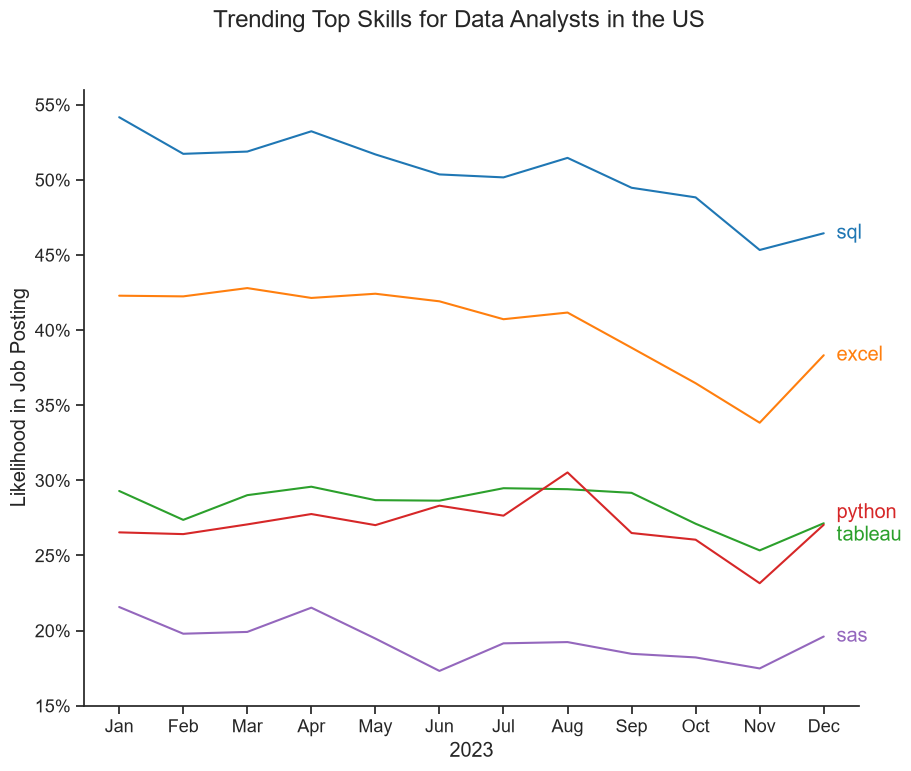

In [48]:
from matplotlib.ticker import PercentFormatter

df_plot = df_DA_US_percent.iloc[:, :5]
fig, ax = plt.subplots(figsize=(10, 8))

sns.lineplot(data=df_plot, dashes=False, palette="tab10", legend=False, ax=ax)
sns.despine()

ax.set_ylabel("Likelihood in Job Posting")
ax.set_xlabel("2023")
ax.set_ylim(15, 56)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))

offsets = {
	"python": 0.8,
	"tableau": -0.8,
}

for i in range(5):
	skill = df_plot.columns[i]
	y = df_plot.iloc[-1, i] + offsets.get(skill, 0)

	ax.text(11.2, y, skill, va="center", color=ax.lines[i].get_color())

fig.suptitle("Trending Top Skills for Data Analysts in the US")
plt.show()